# Predicción temporal de analitos de cristal sin refinar y refinado

Lee `tabla_limpia_valores.xlsx` desde esta misma carpeta y entrena un modelo separado para cada uno de los diez analitos objetivo. La predicción de `t` usa variables independientes rezagadas de `t-1` a `t-W` (por defecto, cinco horas).

- **Sin Refinar:** usa exactamente las variables independientes enumeradas por el usuario.
- **Refinado:** usa todas las columnas independientes incluidas en la tabla y excluye los analitos de ambos cristales. Así no usa analitos sin refinar para predecir los refinados ni incorpora el propio objetivo como predictor.
- La prueba es el último **20% cronológico**; no hay partición aleatoria.
- Los vacíos se conservan. Los textos no numéricos, como `I/O Timeout`, se cuentan y pasan a faltantes solo en la vista numérica en memoria; no se rellenan.

Los intervalos se estiman con regresión por cuantiles y se informa su cobertura empírica en la prueba. No se presupone que la cobertura real sea exactamente 95%.

### 1. Librerías, analitos y variables independientes

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
DATA_FILE = Path("tabla_limpia_valores.xlsx")
DATETIME_COL = "Fecha_hora"
FRACTION_TEST = 0.15
WINDOW_HOURS = 6  # editable; la ventana se compara empíricamente en el otro notebook

TARGETS_SIN_REFINAR = [
    "Cristal sin refinar Cl",
    "Cristal sin refinar SO4",
    "Cristal sin refinar Ca",
    "Cristal sin refinar Mg",
    "Cristal sin refinal ClO4",
]
TARGETS_REFINADO = [
    "Cristal Refinado Cl",
    "Cristal Refinado SO4",
    "Cristal Refinado Ca",
    "Cristal Refinado Mg",
    "Cristal refinado ClO4",
]
ALL_TARGETS = TARGETS_SIN_REFINAR + TARGETS_REFINADO

# Lista independiente indicada para Cristal Sin Refinar.
FEATURES_SIN_REFINAR = [
    "Temp_Cristalización2_A3000",
    "T Cry A3110",
    "Agua de lavado Cf3000",
    "SSK NANO3",
    "SSK CL",
    "SSK SO4",
    "SSK K",
    "SSK MG",
    "SSK CA",
    "SSK KCLO4 IC",
    "SSKCLO4 IC",
    "Flujo SSK",
    "Flujo SSKd",
    "Agua de dilución",
    "Purga_Recirculacion NaNO3",
    "Purga_Recirculación SO4",
    "Purga_Recirculacion K",
    "Purga_Recirculación Ca",
    "Purga_Recirculación Mg",
    "Purga_Recirculación KClO4 IC",
    "Purga_Recirculación ClO4 IC",
]

### 2. Carga del XLSX y revisión de valores no numéricos

In [2]:
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"No encuentro {DATA_FILE}. Ejecuta el notebook desde la carpeta SQM "
        "donde están los notebooks y tabla_limpia_valores.xlsx. "
        f"Carpeta actual: {Path.cwd()}"
    )

raw = pd.read_excel(DATA_FILE, sheet_name=0)
if DATETIME_COL not in raw.columns:
    raise KeyError(f"Falta la columna temporal {DATETIME_COL!r} en {DATA_FILE}")

raw[DATETIME_COL] = pd.to_datetime(raw[DATETIME_COL], errors="coerce")
invalid_time_rows = int(raw[DATETIME_COL].isna().sum())
raw = raw.dropna(subset=[DATETIME_COL]).sort_values(DATETIME_COL).copy()
if raw[DATETIME_COL].duplicated().any():
    duplicated = raw.loc[raw[DATETIME_COL].duplicated(keep=False), DATETIME_COL]
    raise ValueError(f"Hay timestamps duplicados en destino: {duplicated.head().tolist()}")

numeric_cols = [c for c in raw.columns if c != DATETIME_COL]
raw_numeric = raw[numeric_cols].copy()
numeric = raw_numeric.apply(pd.to_numeric, errors="coerce")
coercion_mask = raw_numeric.notna() & numeric.isna()
coercion_report = coercion_mask.sum().loc[lambda s: s > 0].rename("textos_no_numericos_convertidos_a_faltante")

# No se imputan ni interpolan celdas vacías. HistGradientBoostingRegressor maneja NaN.
df = numeric.copy()
df.index = pd.DatetimeIndex(raw[DATETIME_COL], name=DATETIME_COL)
df = df.sort_index()

missing_columns = [c for c in FEATURES_SIN_REFINAR + ALL_TARGETS if c not in df.columns]
if missing_columns:
    raise KeyError(f"Faltan columnas requeridas en el XLSX: {missing_columns}")

# Para Cristal Refinado se usan todas las columnas cuantitativas disponibles,
# excluyendo los analitos de ambos productos para evitar fuga del objetivo.
FEATURES_REFINADO = [c for c in df.columns if c not in ALL_TARGETS]

cutoff_position = int(np.floor((1 - FRACTION_TEST) * len(df.index)))
cutoff_time = df.index[cutoff_position]
print(f"Archivo: {DATA_FILE.resolve()}")
print(f"Filas temporales: {len(df):,}; período: {df.index.min()} a {df.index.max()}")
print(f"Corte temporal: {cutoff_time}; prueba = último {FRACTION_TEST:.0%} del calendario")
print(f"Filas con fecha inválida excluidas: {invalid_time_rows}")
print(f"Variables independientes Sin Refinar: {len(FEATURES_SIN_REFINAR)}")
print(f"Variables independientes Refinado: {len(FEATURES_REFINADO)}")
if len(coercion_report):
    display(coercion_report.to_frame())
else:
    print("Textos no numéricos en columnas de datos: ninguno")

Archivo: /mnt/c/Users/SrLeo/Desktop/SQM/Predicción efecto de analitos/tabla_limpia_valores.xlsx
Filas temporales: 8,379; período: 2025-01-01 01:00:00 a 2025-12-16 04:00:00
Corte temporal: 2025-10-24 19:00:00; prueba = último 15% del calendario
Filas con fecha inválida excluidas: 0
Variables independientes Sin Refinar: 21
Variables independientes Refinado: 32


,textos_no_numericos_convertidos_a_faltante
Temp_Cristalización2_A3000,16
T Cry A3110,39
Temperatura ml refinación,34
Temperatura TK 6110,95
Temperatura TK6160,95
Agua de lavado Cf3000,16
Agua de lavado Cf 6000,97
Flujo SSK,40
Flujo SSKd,40
Agua de dilución,40


### 3. Función de lags y partición temporal

In [3]:
def crear_split_temporal(data, features, target, window_size, cutoff):
    """Predice y(t) con variables independientes de t-1 a t-window_size."""
    X = pd.DataFrame(index=data.index)
    for lag in range(1, window_size + 1):
        for col in features:
            X[f"{col}__lag_{lag}h"] = data[col].shift(lag)
    y = data[target]

    # Conserva faltantes parciales; elimina solo objetivos ausentes o filas sin ningún predictor.
    keep = y.notna() & X.notna().any(axis=1)
    X, y = X.loc[keep], y.loc[keep]
    train_mask = X.index < cutoff
    test_mask = X.index >= cutoff
    X_train, X_test = X.loc[train_mask].copy(), X.loc[test_mask].copy()
    y_train, y_test = y.loc[train_mask].copy(), y.loc[test_mask].copy()

    # Una columna completamente vacía en entrenamiento no aporta y puede impedir el ajuste.
    usable = X_train.columns[X_train.notna().any(axis=0)]
    X_train, X_test = X_train.loc[:, usable], X_test.loc[:, usable]
    return X_train, X_test, y_train, y_test


def metricas(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    std = float(np.std(y_true, ddof=0))
    return {
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan,
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": rmse,
        "NRMSE": rmse / std if std > 0 else np.nan,
    }

### 4. Entrenamiento y evaluación de los diez objetivos

In [4]:
MIN_TRAIN_ROWS = 50
MIN_TEST_ROWS = 2
models = {}
metric_rows = []
prediction_rows = []
skipped_targets = []

for product, targets, features in [
    ("Sin Refinar", TARGETS_SIN_REFINAR, FEATURES_SIN_REFINAR),
    ("Refinado", TARGETS_REFINADO, FEATURES_REFINADO),
]:
    for target in targets:
        X_train, X_test, y_train, y_test = crear_split_temporal(
            df, features, target, WINDOW_HOURS, cutoff_time
        )
        if len(X_train) < MIN_TRAIN_ROWS or len(X_test) < MIN_TEST_ROWS or X_train.shape[1] == 0:
            skipped_targets.append({"Producto": product, "Analito": target,
                                    "n_entrenamiento": len(y_train), "n_prueba": len(y_test)})
            continue

        model = HistGradientBoostingRegressor(
            max_iter=200, l2_regularization=1.0, random_state=SEED
        ).fit(X_train, y_train)
        model_low = HistGradientBoostingRegressor(
            loss="quantile", quantile=0.025, max_iter=200,
            l2_regularization=1.0, random_state=SEED
        ).fit(X_train, y_train)
        model_high = HistGradientBoostingRegressor(
            loss="quantile", quantile=0.975, max_iter=200,
            l2_regularization=1.0, random_state=SEED
        ).fit(X_train, y_train)

        pred = model.predict(X_test)
        q_low = model_low.predict(X_test)
        q_high = model_high.predict(X_test)
        lower = np.minimum(q_low, q_high)
        upper = np.maximum(q_low, q_high)
        scores = metricas(y_test, pred)
        coverage = float(((y_test.to_numpy() >= lower) & (y_test.to_numpy() <= upper)).mean())
        metric_rows.append({
            "Producto": product, "Analito": target,
            "n_entrenamiento": len(y_train), "n_prueba": len(y_test),
            "Inicio_prueba": y_test.index.min(), "Fin_prueba": y_test.index.max(),
            **scores, "Cobertura_intervalo": coverage,
        })
        for timestamp, actual, point, lo, hi in zip(y_test.index, y_test, pred, lower, upper):
            prediction_rows.append({
                "Fecha_hora": timestamp, "Producto": product, "Analito": target,
                "Real": float(actual), "Predicción": float(point),
                "P2.5": float(lo), "P97.5": float(hi),
            })
        models[target] = {
            "Producto": product, "modelo": model,
            "X_test": X_test, "y_test": y_test,
        }

metricas_test = pd.DataFrame(metric_rows).sort_values(["Producto", "Analito"])
predicciones = pd.DataFrame(prediction_rows).sort_values(["Fecha_hora", "Producto", "Analito"])
if not skipped_targets:
    print("Todos los objetivos superaron el mínimo de muestras configurado.")
else:
    print("Objetivos omitidos por insuficiencia de datos:")
    display(pd.DataFrame(skipped_targets))
display(metricas_test)
print(f"Predicciones de prueba generadas: {len(predicciones):,}")

/tmp/ipykernel_7540/828488867.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[f"{col}__lag_{lag}h"] = data[col].shift(lag)
/tmp/ipykernel_7540/828488867.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[f"{col}__lag_{lag}h"] = data[col].shift(lag)
/tmp/ipykernel_7540/828488867.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented 

Todos los objetivos superaron el mínimo de muestras configurado.


,Producto,Analito,n_entrenamiento,n_prueba,Inicio_prueba,Fin_prueba,R2,MAE,RMSE,NRMSE,Cobertura_intervalo
7,Refinado,Cristal Refinado Ca,3612,649,2025-10-24 19:00:00,2025-12-16 01:00:00,-0.123455,0.006412,0.007670,1.059931,0.956857
5,Refinado,Cristal Refinado Cl,3479,612,2025-10-24 19:00:00,2025-12-16 01:00:00,-137.555998,0.069149,0.127080,11.770981,0.810458
8,Refinado,Cristal Refinado Mg,3615,649,2025-10-24 19:00:00,2025-12-16 01:00:00,0.023290,0.002190,0.003043,0.988286,0.847458
6,Refinado,Cristal Refinado SO4,3430,649,2025-10-24 19:00:00,2025-12-16 01:00:00,-0.045644,0.057231,0.077761,1.022567,0.714946
9,Refinado,Cristal refinado ClO4,3434,649,2025-10-24 19:00:00,2025-12-16 01:00:00,-0.171008,14.505144,22.597977,1.082131,0.950693
4,Sin Refinar,Cristal sin refinal ClO4,3267,560,2025-10-24 19:00:00,2025-12-16 01:00:00,0.071179,270.451516,389.505154,0.963753,0.662500
2,Sin Refinar,Cristal sin refinar Ca,2923,611,2025-10-24 19:00:00,2025-12-16 01:00:00,-0.104365,0.009632,0.011470,1.050888,0.965630
0,Sin Refinar,Cristal sin refinar Cl,3270,611,2025-10-24 19:00:00,2025-12-16 01:00:00,-0.857287,0.284423,0.564468,1.362823,0.747954
3,Sin Refinar,Cristal sin refinar Mg,3271,609,2025-10-24 19:00:00,2025-12-16 01:00:00,0.652817,0.021195,0.027888,0.589223,0.663383
1,Sin Refinar,Cristal sin refinar SO4,3273,611,2025-10-24 19:00:00,2025-12-16 01:00:00,-0.072559,0.093642,0.123479,1.035644,0.626841


Predicciones de prueba generadas: 6,210


### 5. Resumen mensual dentro de la ventana de prueba

In [5]:
if not predicciones.empty:
    predicciones["Mes"] = predicciones["Fecha_hora"].dt.to_period("M").astype(str)
    monthly_rows = []
    for (product, target, month), group in predicciones.groupby(["Producto", "Analito", "Mes"]):
        scores = metricas(group["Real"], group["Predicción"])
        coverage = ((group["Real"] >= group["P2.5"]) & (group["Real"] <= group["P97.5"])).mean()
        monthly_rows.append({"Producto": product, "Analito": target, "Mes": month,
                             "n_prueba": len(group), **scores,
                             "Cobertura_intervalo": float(coverage)})
    metricas_mensuales = pd.DataFrame(monthly_rows).sort_values(["Producto", "Analito", "Mes"])
    display(metricas_mensuales)

,Producto,Analito,Mes,n_prueba,R2,MAE,RMSE,NRMSE,Cobertura_intervalo
0,Refinado,Cristal Refinado Ca,2025-10,83,-2.674051,0.005287,0.006235,1.916781,1.000000
1,Refinado,Cristal Refinado Ca,2025-11,382,-0.355418,0.007135,0.008341,1.164224,0.937173
2,Refinado,Cristal Refinado Ca,2025-12,184,0.272923,0.005420,0.006750,0.852688,0.978261
3,Refinado,Cristal Refinado Cl,2025-10,77,-445.559030,0.141631,0.211942,21.131943,0.766234
4,Refinado,Cristal Refinado Cl,2025-11,359,-107.058848,0.059163,0.113812,10.395136,0.766017
5,Refinado,Cristal Refinado Cl,2025-12,176,-106.245315,0.057808,0.100407,10.355931,0.920455
6,Refinado,Cristal Refinado Mg,2025-10,83,-0.853188,0.002507,0.003517,1.361319,0.759036
7,Refinado,Cristal Refinado Mg,2025-11,382,0.061690,0.002286,0.003107,0.968664,0.821990
8,Refinado,Cristal Refinado Mg,2025-12,184,-0.018981,0.001850,0.002655,1.009446,0.940217
9,Refinado,Cristal Refinado SO4,2025-10,83,-0.095968,0.030437,0.038316,1.046885,0.939759


### 6. Predicciones e intervalos en el tramo reservado

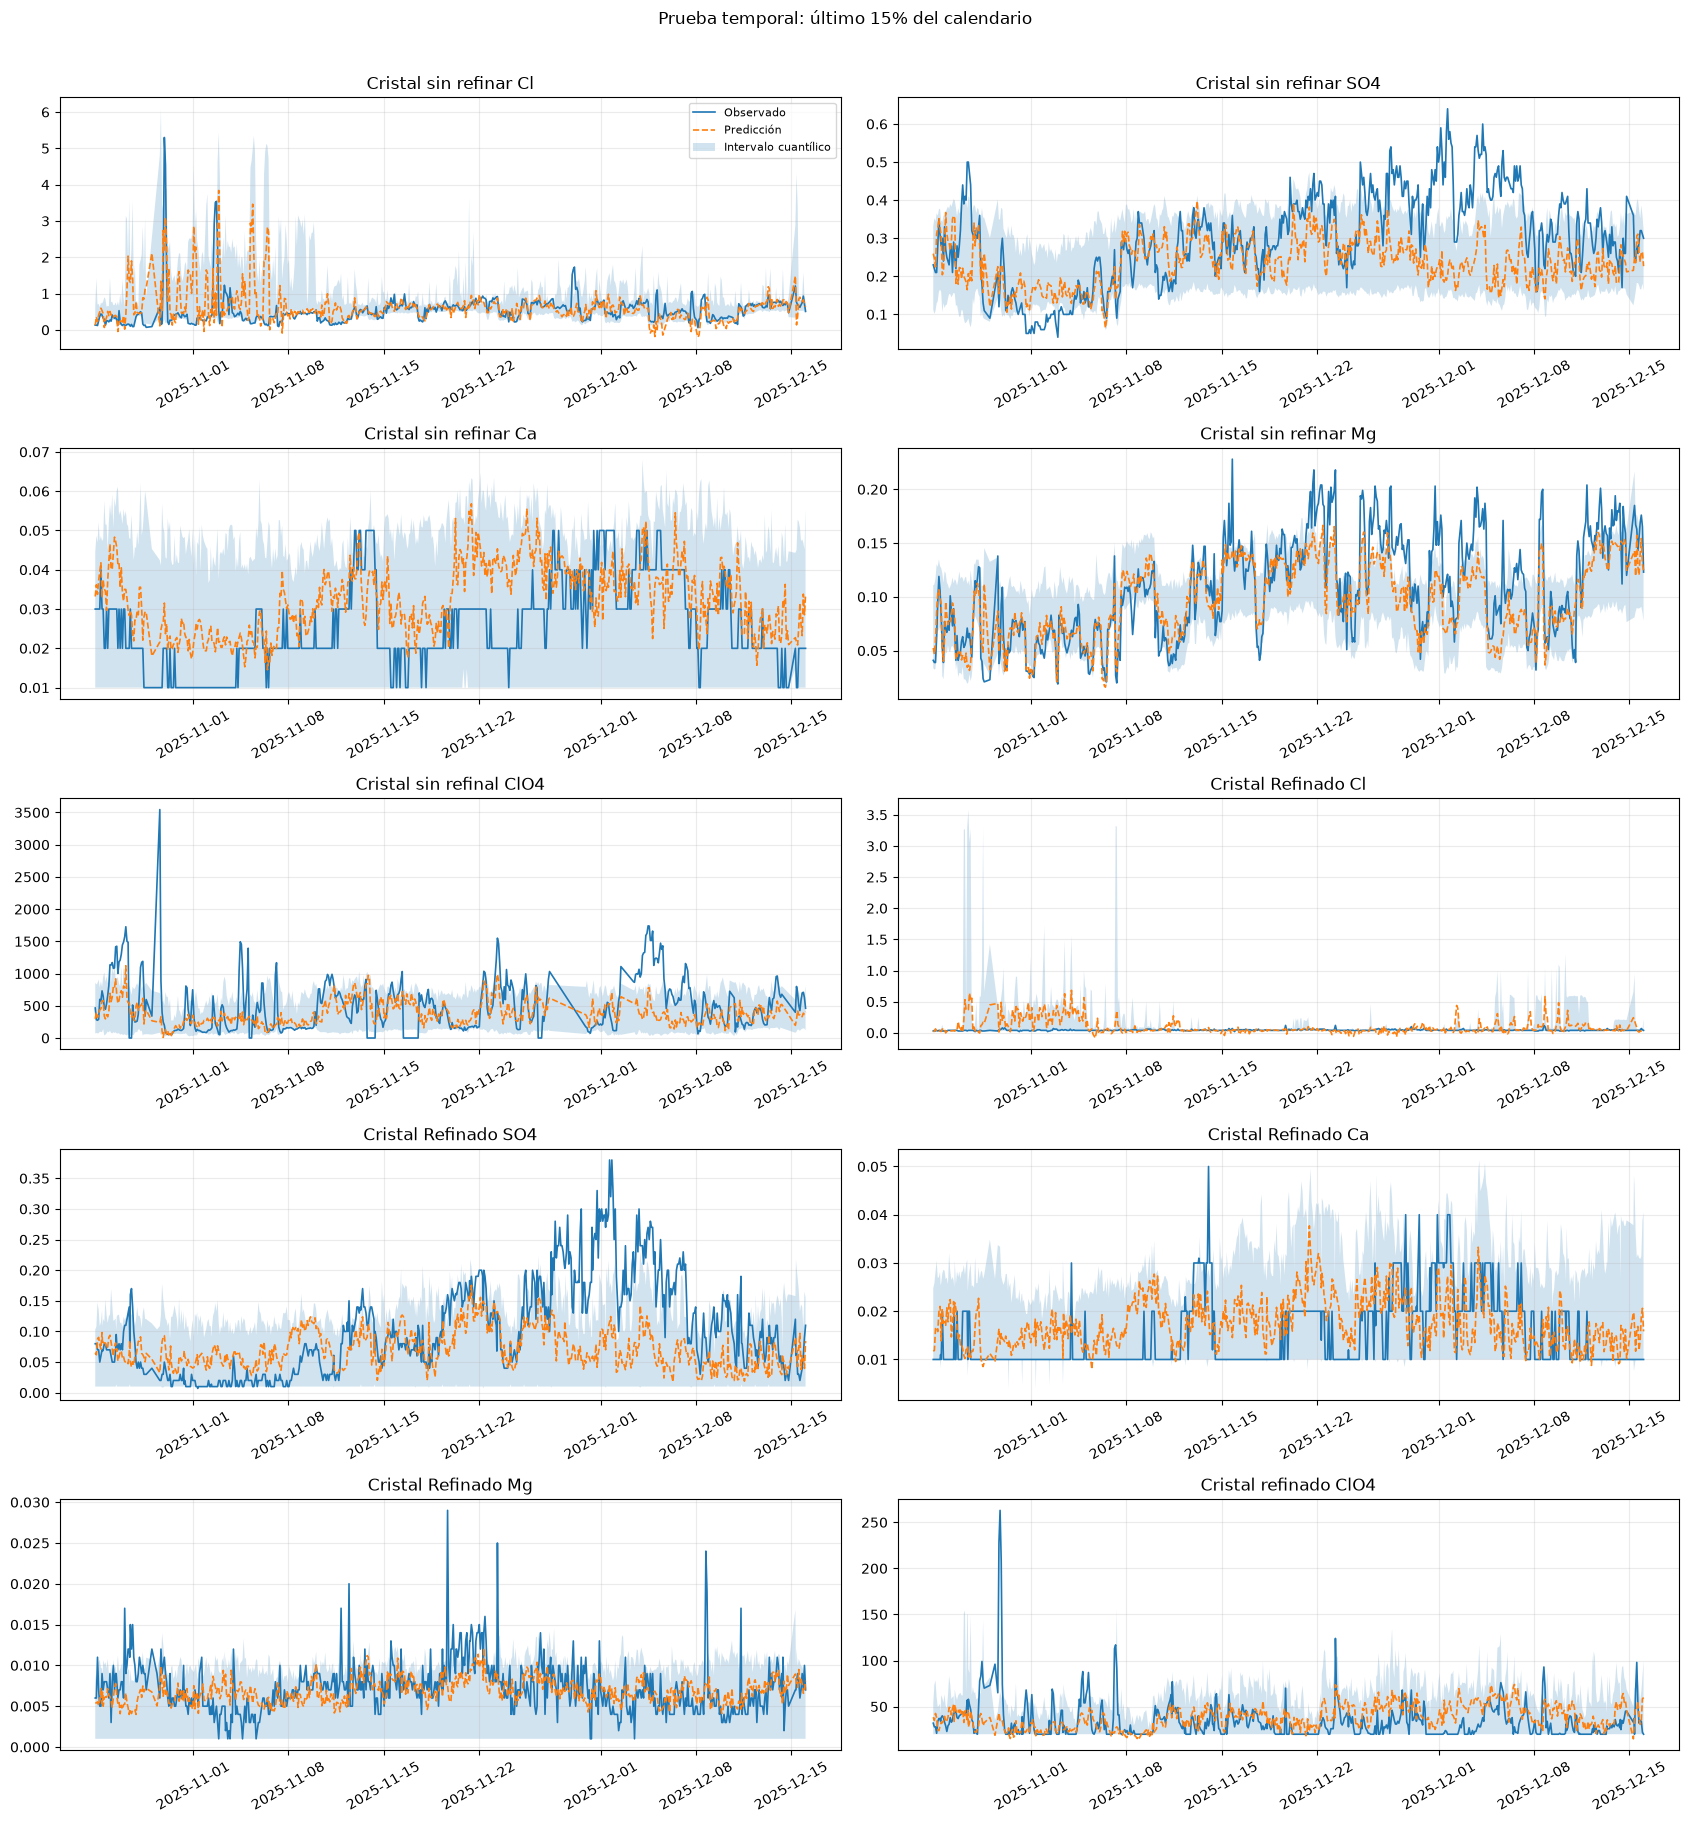

In [6]:
if not predicciones.empty:
    fig, axes = plt.subplots(5, 2, figsize=(17, 18), sharex=False)
    for ax, target in zip(axes.ravel(), ALL_TARGETS):
        sub = predicciones[predicciones["Analito"] == target].sort_values("Fecha_hora")
        if sub.empty:
            ax.set_title(f"{target} — sin suficientes datos")
            ax.axis("off")
            continue
        ax.plot(sub["Fecha_hora"], sub["Real"], label="Observado", linewidth=1.2)
        ax.plot(sub["Fecha_hora"], sub["Predicción"], label="Predicción", linestyle="--", linewidth=1.2)
        ax.fill_between(sub["Fecha_hora"], sub["P2.5"], sub["P97.5"], alpha=0.2, label="Intervalo cuantílico")
        ax.set_title(target)
        ax.tick_params(axis="x", rotation=30)
        ax.grid(True, alpha=0.25)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"Prueba temporal: último {FRACTION_TEST:.0%} del calendario", y=1.01)
    plt.tight_layout()
    plt.show()

### 7. Importancia por permutación de variables independientes

,Producto,Analito,Variable,Importancia_R2
0,Refinado,Cristal Refinado Ca,SSK CA,0.059323
1,Refinado,Cristal Refinado Ca,Purga_Recirculación Mg,0.036103
2,Refinado,Cristal Refinado Ca,Temperatura TK 6110,0.026042
3,Refinado,Cristal Refinado Ca,Purga_Recirculación KClO4 IC,0.025879
4,Refinado,Cristal Refinado Ca,Agua de lavado Cf3000,0.018825
5,Refinado,Cristal Refinado Ca,ML_REFI_SO4,0.018302
6,Refinado,Cristal Refinado Ca,SSK K,0.017371
7,Refinado,Cristal Refinado Ca,Purga_Recirculación Ca,0.016007
8,Refinado,Cristal Refinado Ca,T Cry A3110,0.014984
9,Refinado,Cristal Refinado Ca,Flujo SSK,0.013270


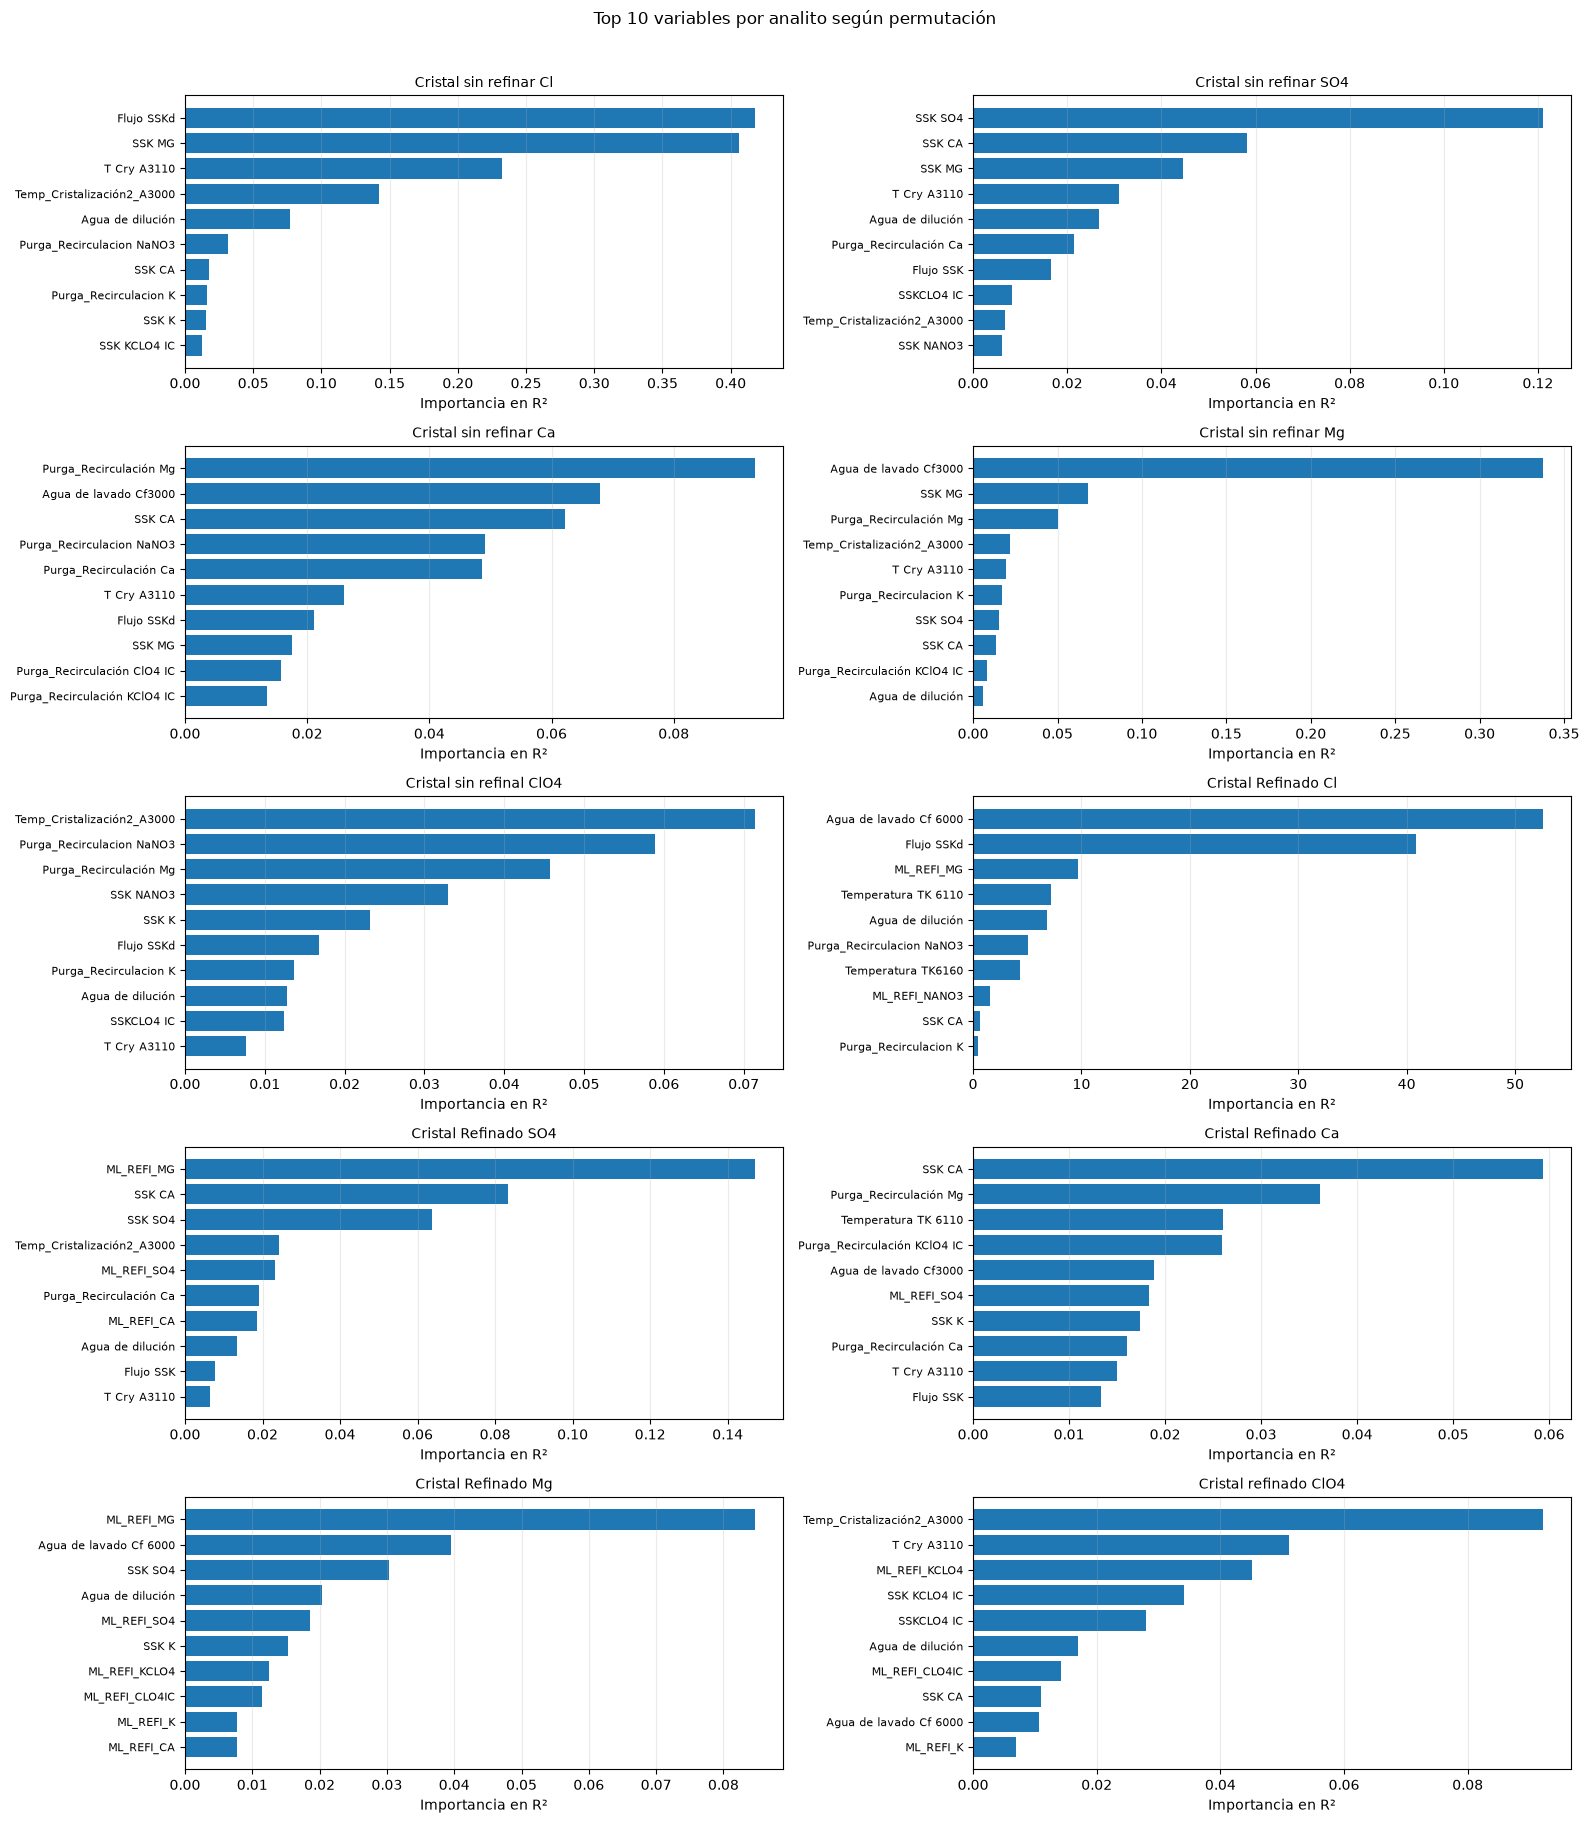

In [13]:
importance_rows = []
for target, info in models.items():
    if len(info["y_test"]) < 2:
        continue
    perm = permutation_importance(
        info["modelo"], info["X_test"], info["y_test"],
        n_repeats=3, random_state=SEED, scoring="r2",
    )
    by_feature = {}
    for column, value in zip(info["X_test"].columns, perm.importances_mean):
        base_feature = column.rsplit("__lag_", 1)[0]
        by_feature[base_feature] = by_feature.get(base_feature, 0.0) + float(value)
    for feature, importance in by_feature.items():
        importance_rows.append({
            "Producto": info["Producto"],
            "Analito": target,
            "Variable": feature,
            "Importancia_R2": importance,
        })

importancias = pd.DataFrame(importance_rows)
if importancias.empty:
    print("No hay suficientes datos para calcular importancias por permutación.")
else:
    importancias = (
        importancias
        .sort_values(["Producto", "Analito", "Importancia_R2"], ascending=[True, True, False])
        .reset_index(drop=True)
    )

    top_importancias = (
        importancias
        .groupby(["Producto", "Analito"], group_keys=False)
        .head(10)
        .reset_index(drop=True)
    )
    with pd.option_context("display.max_rows", 100, "display.max_columns", None):
        display(top_importancias)

    fig, axes = plt.subplots(5, 2, figsize=(16, 18), sharex=False)
    for ax, target in zip(axes.ravel(), ALL_TARGETS):
        subset = (
            importancias[importancias["Analito"] == target]
            .nlargest(10, "Importancia_R2")
            .sort_values("Importancia_R2")
        )
        if subset.empty:
            ax.set_title(f"{target} — sin datos")
            ax.axis("off")
            continue
        ax.barh(subset["Variable"], subset["Importancia_R2"])
        ax.set_title(target, fontsize=10)
        ax.set_xlabel("Importancia en R²")
        ax.tick_params(axis="y", labelsize=8)
        ax.grid(axis="x", alpha=0.25)

    fig.suptitle("Top 10 variables por analito según permutación", y=1.01)
    plt.tight_layout()
    plt.show()

In [8]:
from pathlib import Path 
import pandas as pd

carpeta = Path("resultados_modelo")
carpeta.mkdir(exist_ok=True)

with pd.ExcelWriter(carpeta / "resultados_prediccion.xlsx") as writer:
    metricas_test.to_excel(writer, sheet_name="Metricas", index=False)
    predicciones.to_excel(writer, sheet_name="Predicciones", index=False)

    if "metricas_mensuales" in globals():
        metricas_mensuales.to_excel(
            writer, sheet_name="Metricas mensuales", index=False
        )

    if "importancias" in globals() and not importancias.empty:
        importancias.to_excel(writer, sheet_name="Importancias", index=False)

### 8. Alcance de la validación

La puntuación representa una **predicción de una hora adelante**: los valores de entrada terminan en `t-1` y el objetivo se mide en `t`. El corte usa el mismo timestamp para todos los analitos y reserva el último 20% del calendario. Solo se puntúan objetivos efectivamente observados, por lo que el número de pruebas puede variar por analito.

Los vacíos de predictores se entregan como `NaN` al estimador; no se rellenan. Las métricas y la importancia por permutación describen desempeño predictivo en este corte, no demuestran causalidad. La cobertura del intervalo se calcula sobre la prueba y debe revisarse junto con MAE/RMSE.